# Pattern Recognition 1 - Expert System

**Objectives**

* Create a working image analysis and pattern recognition pipeline
* Object labelisation and feature extraction
* Creating an Expert System for Optical Character Recognition (OCR)

**Libraries needed for this lab**

* Numpy
* Matplotlib
* Scikit-image

(all included in the Anaconda distribution)

## Object detection

Given the following image :

(851, 1068) uint8


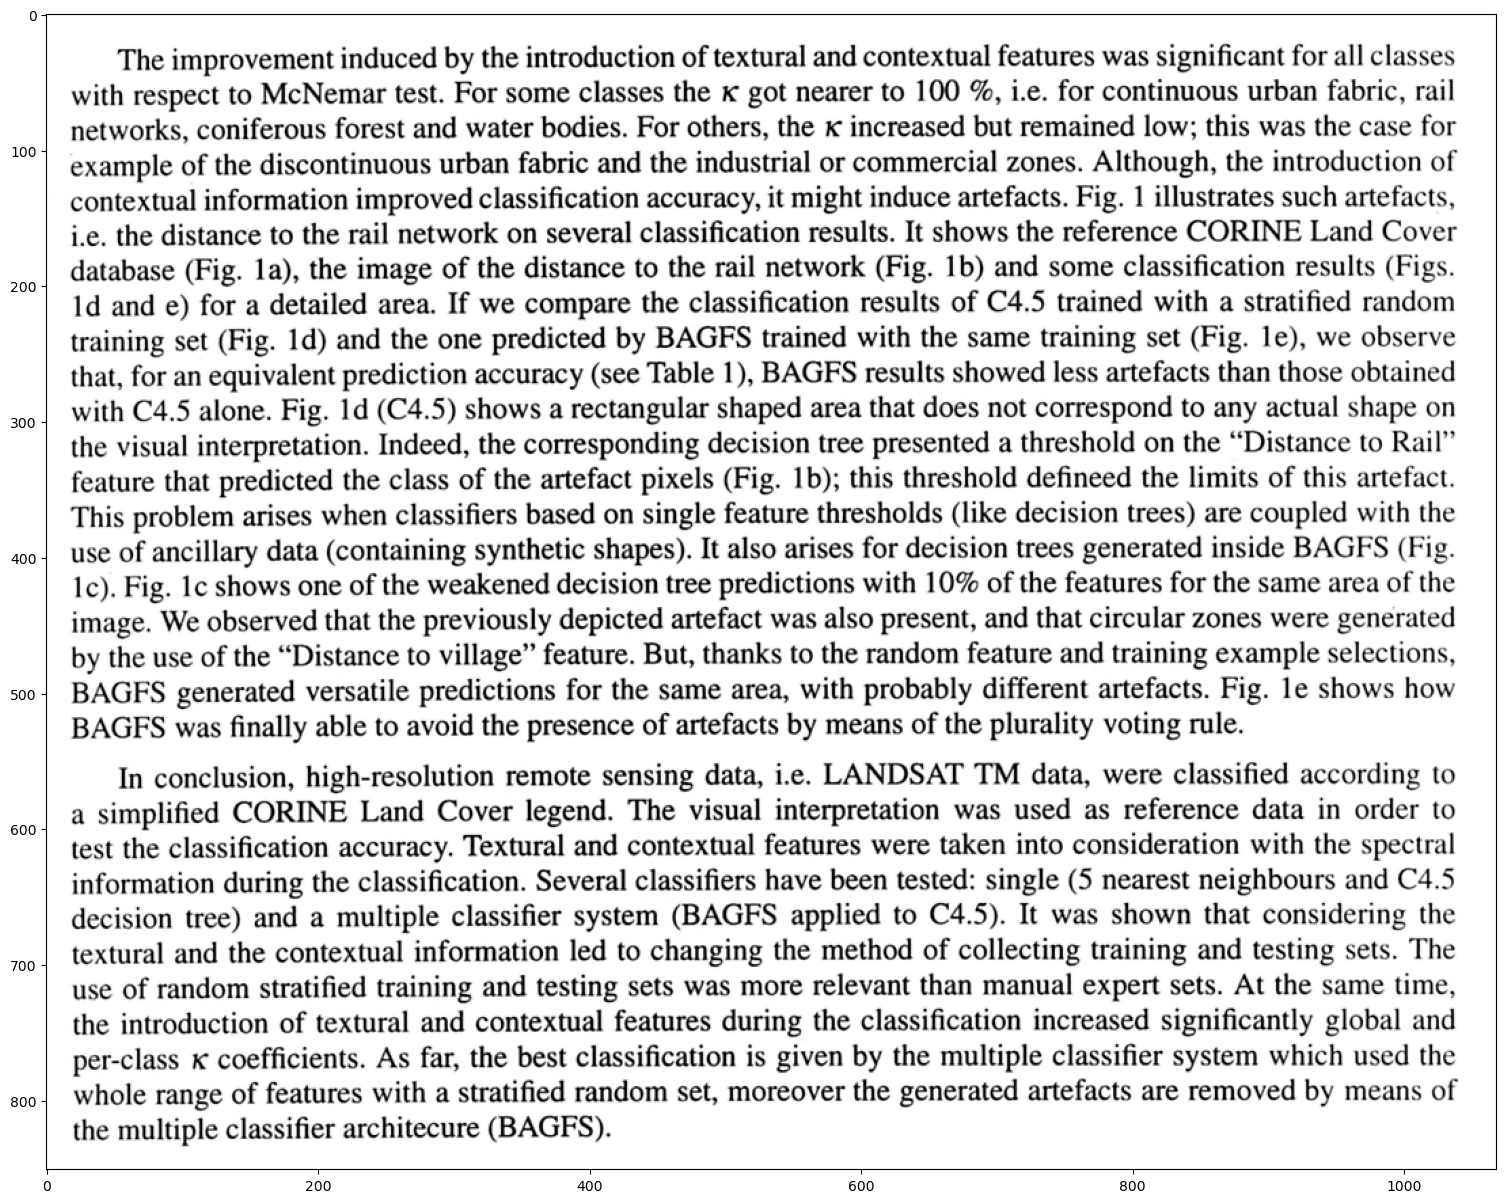

In [326]:
import numpy as np
from matplotlib import pyplot as plt
from skimage.io import imread
%matplotlib inline

im = imread('../data/doc1.png')
print(im.shape, im.dtype)

plt.figure(figsize=(20,15))
plt.imshow(im, cmap=plt.cm.gray)
plt.show()

In [327]:
from skimage.io import imread
from skimage import color


# before perform every calculations we need to setup the image (because typically is not provided as gray scale image)

def read_image(path):
    
    # loading of general image
    im = imread(path)
    
    # 1. check about his dimension (what we want is RGB )
    if im.ndim == 3:
        # if have more than 3 dimension we should convert in RGB gray scale
        if im.shape[2] == 4:
            im = color.rgba2rgb(im)
            
        # converison 
        im_gray = color.rgb2gray(im) * 255
        return im_gray.astype(np.uint8)
        
    else:
        return im

0 255


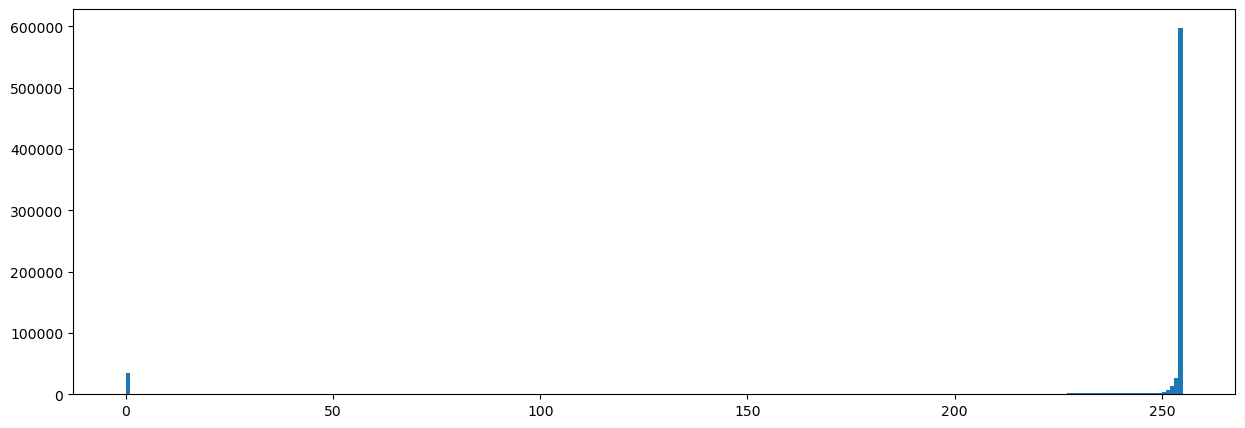

In [328]:
print(im.min(), im.max())
plt.figure(figsize=(15,5))
plt.hist(im.flatten(), bins=255)
plt.show()


# this plot show the distribution of pixel between 0 and 255
# usually: 
# - 0 is black (foreground)
# - 255 is white (background)

# instead using this distribution, we can use a threshold to separate foreground and background. (like mid-point 127 or maybe almost something very close to 127)

Threshold Otsu: 154


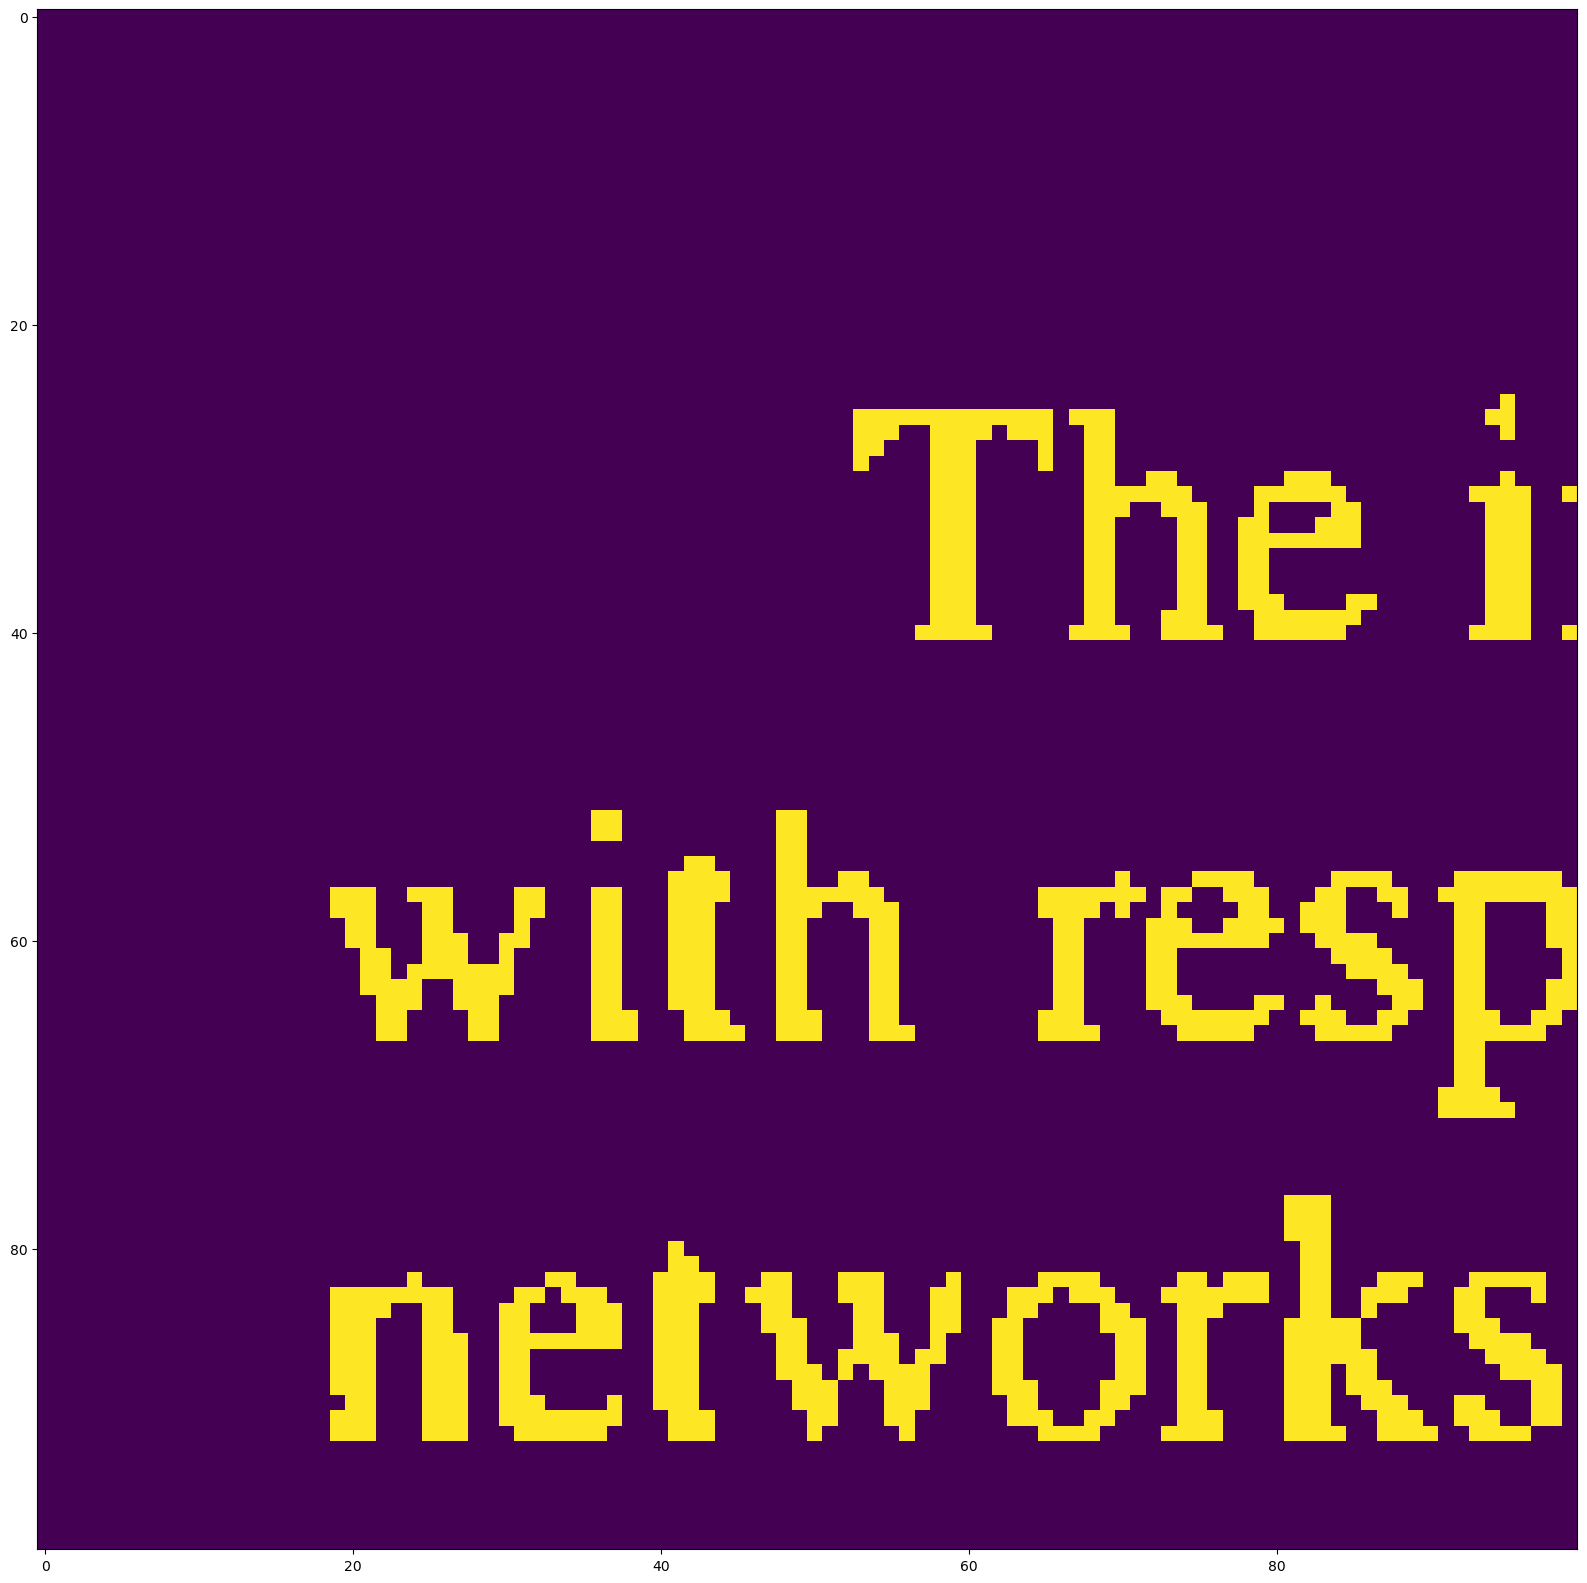

In [329]:
from skimage.filters import threshold_otsu
threshold = threshold_otsu(im)
print(f"Threshold Otsu: {threshold}")

segmented = im < threshold

plt.figure(figsize=(20,20))
plt.imshow(segmented[:100, :100])
plt.show()

# to improve segmented image we use threshold otsu (function used to find the correct threshold for segmenting an image)


In [330]:
def get_segmented_image(im):
    threshold = threshold_otsu(im)
    return im < threshold

* **Segment** the image to isolate the text from the background
* **Label individual characters** and **extract** the centroid position, the bounding box, and useful features for each character.

Useful documentation: [`skimage.measure`](http://scikit-image.org/docs/dev/api/skimage.measure.html) module.

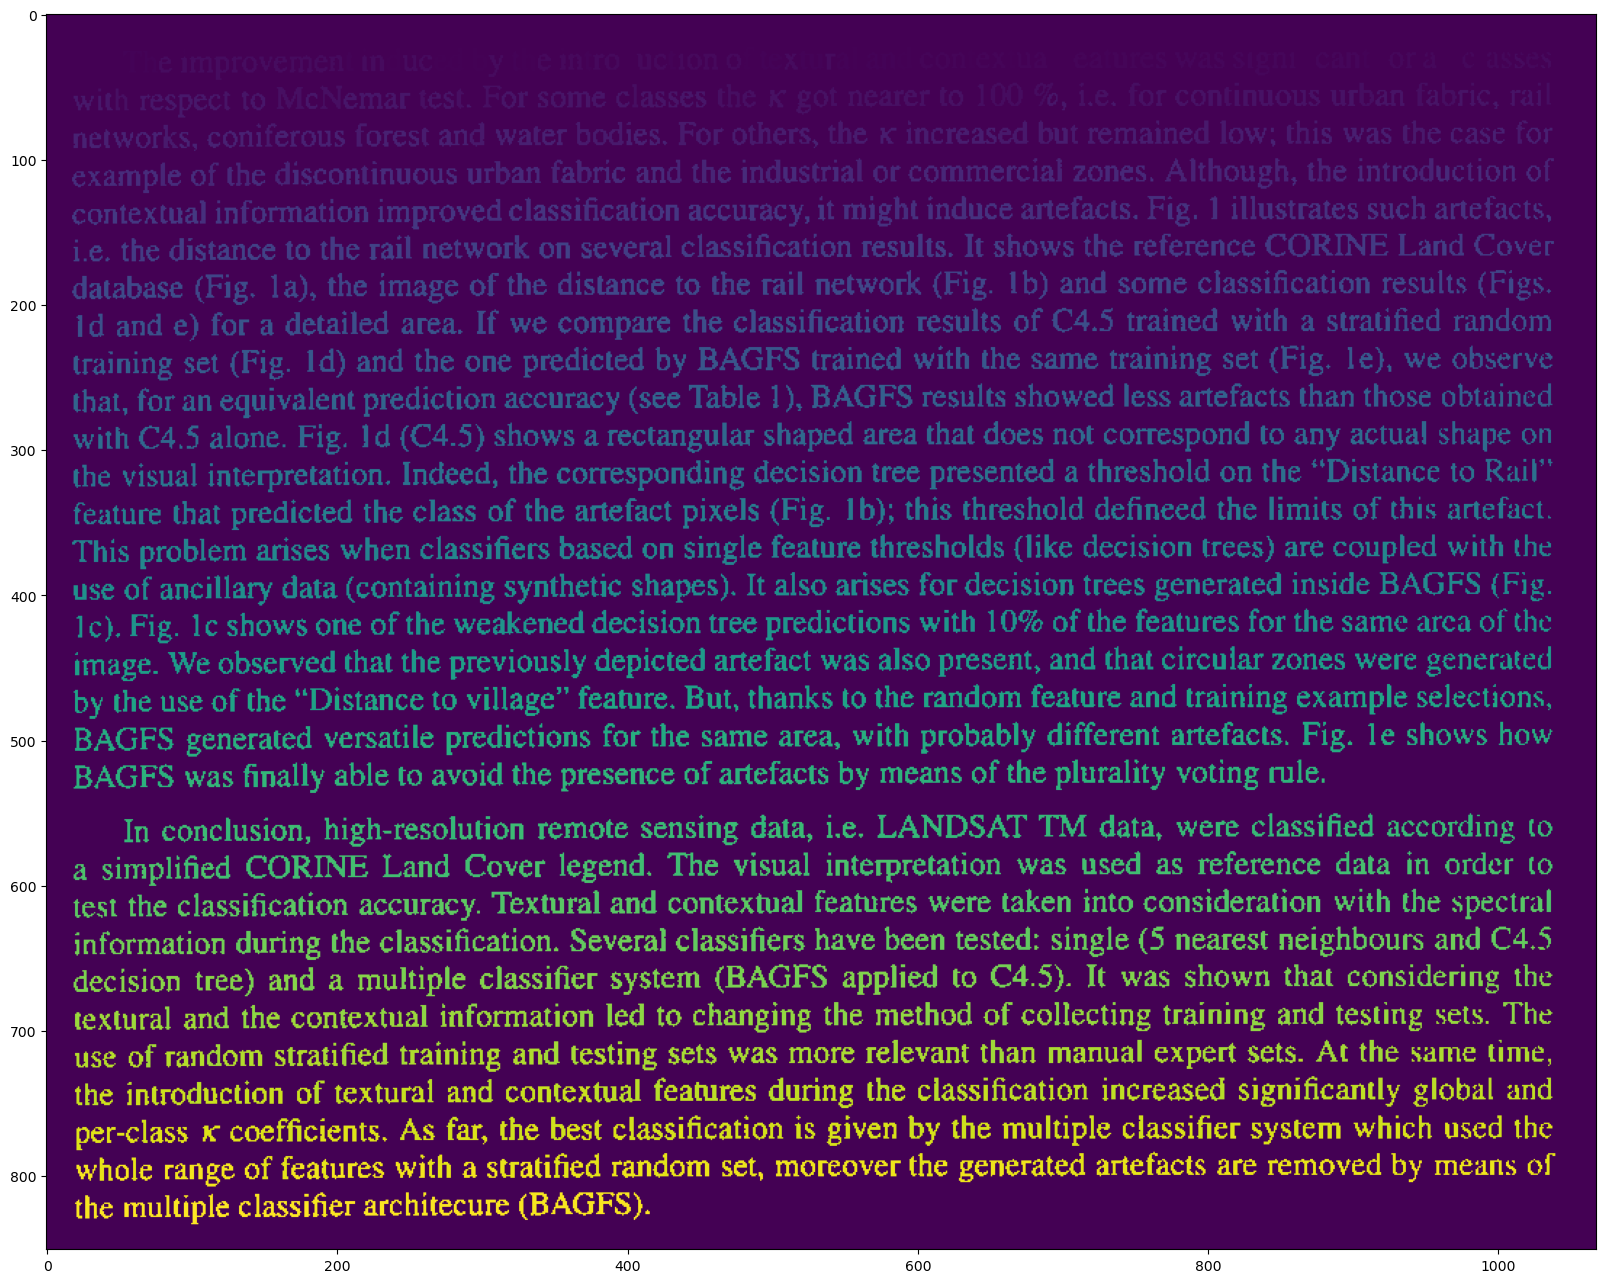

In [331]:
# now we are going to evaluate the measure label

from skimage.measure import label



label_image = label(segmented)
plt.figure(figsize=(20,20))
#plt.imshow(label_image[:100, :100])
plt.imshow(label_image)
plt.show()



# what is the maning of label method?
# for each pixel of character "T" with a specific integer value, connect every pixel with the same value and assign a unique label to each connected component.


# Of course for some letter like "i" the are two objects separated


# suppose now we want to extract some information using the position of this letter.

In [332]:
def get_label_image(segmented):
    return label(segmented)


In [333]:
from skimage.measure import  regionprops

objects_props = regionprops(label_image)

In [334]:
def get_objects_properties(label_image):
    return regionprops(label_image)


In [335]:
for obj in objects_props:
    print(obj['centroid'], obj['bbox'])
    break


# output: position of centroid (x, y) and bounding box (min_row, min_col, max_row, max_col)



(np.float64(30.142857142857142), np.float64(692.5142857142857)) (22, 691, 38, 695)


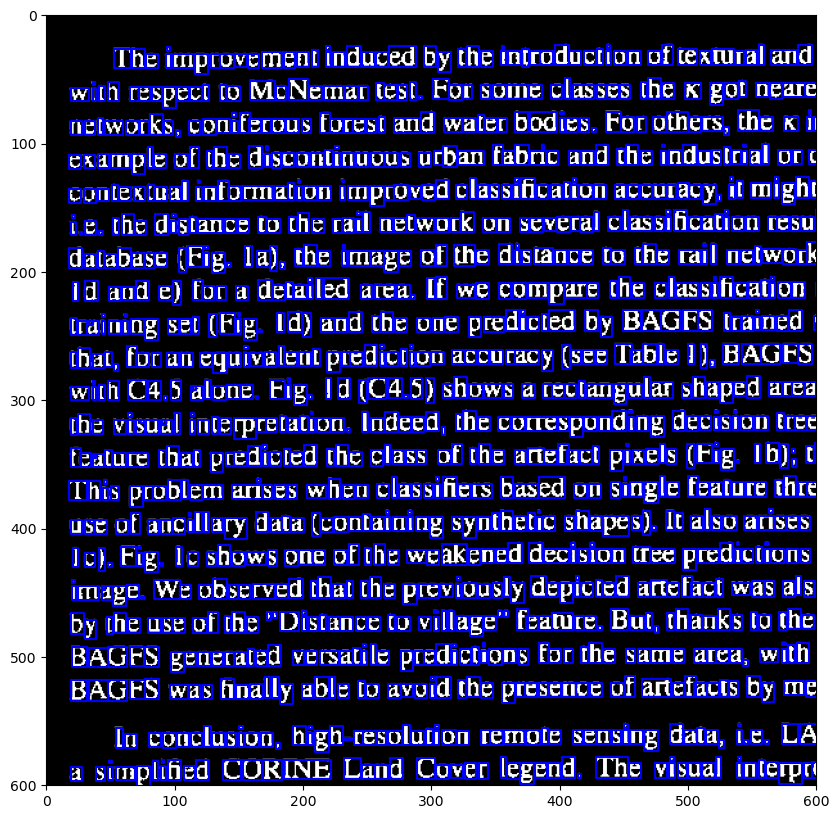

In [336]:
import math

# here we develop a simple expert that recognise the letter  


fig, ax = plt.subplots(figsize=(20,10))
ax.imshow(segmented, cmap=plt.cm.gray)


for props in objects_props:
    minr, minc, maxr, maxc = props.bbox
    bx = (minc, maxc, maxc, minc, minc)
    by = (minr, minr, maxr, maxr, minr)
    ax.plot(bx, by, '-b', linewidth=1.5)

ax.axis((0, 600, 600, 0))
plt.show()

## Line detection and letter ordering

* Find the labels (objects) that belong to each text line
* Order each character in a text line from left to right

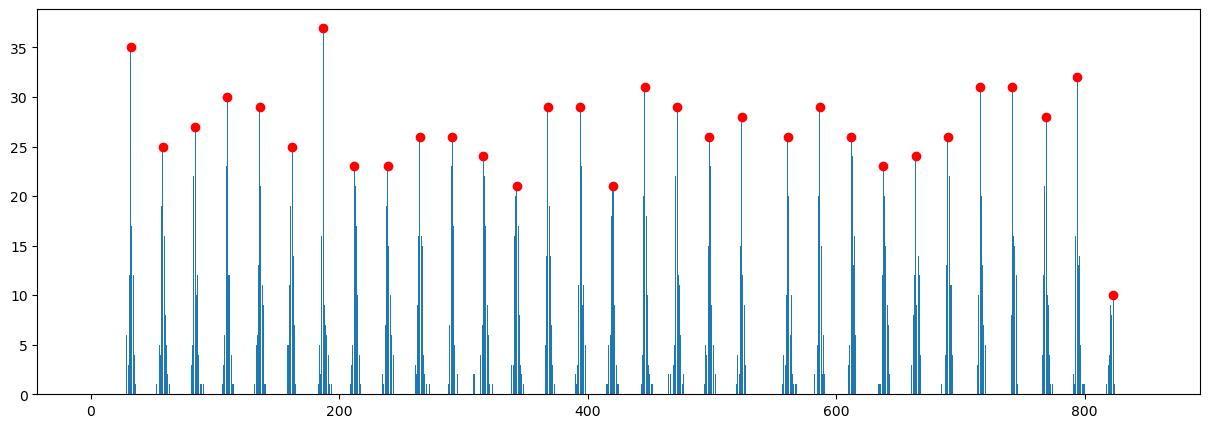

In [337]:
# goal: find the rule that determine a groups of letter

centroid_ys = np.zeros((im.shape[0]))
# shape[0] is the number of row in the image

for obj in objects_props:
    if obj.area < 8:
        continue
    centroid_ys[int(obj['centroid'][0])] += 1
    # this count for each object the vertical position of centroid


maxima =[]

for y in range(3, im.shape[0]-3):
    if centroid_ys[y] == centroid_ys[y-3:y+3].max() and centroid_ys[y] > 2 and y-1 not in maxima:
        # we are checking about the current value is the maximum of a range of (-3, 3) and also we use a treshold to avoid noise
        maxima.append(y)

plt.figure(figsize=(15,5))
plt.bar(range(im.shape[0]), centroid_ys)
for m in maxima:
    plt.plot(m, centroid_ys[m], 'ro')
plt.show()

# the result show for each line the number the number of objects that we have

# we can also filter some object that are going to avoid the number of object detecteded that inside the plot is showed by some discontinuity 




In [338]:
def get_centroid_ys(objects_props, im):
    centroid_ys = np.zeros((im.shape[0]))
    for obj in objects_props:
        if obj.area < 8:
            continue
        centroid_ys[int(obj['centroid'][0])] += 1
    return centroid_ys

def line_maxima(centroid_ys):
    maxima =[]
    for y in range(3, len(centroid_ys)-3):
        if centroid_ys[y] == centroid_ys[y-3:y+3].max() and centroid_ys[y] > 2 and y-1 not in maxima:
            maxima.append(y)
    return maxima

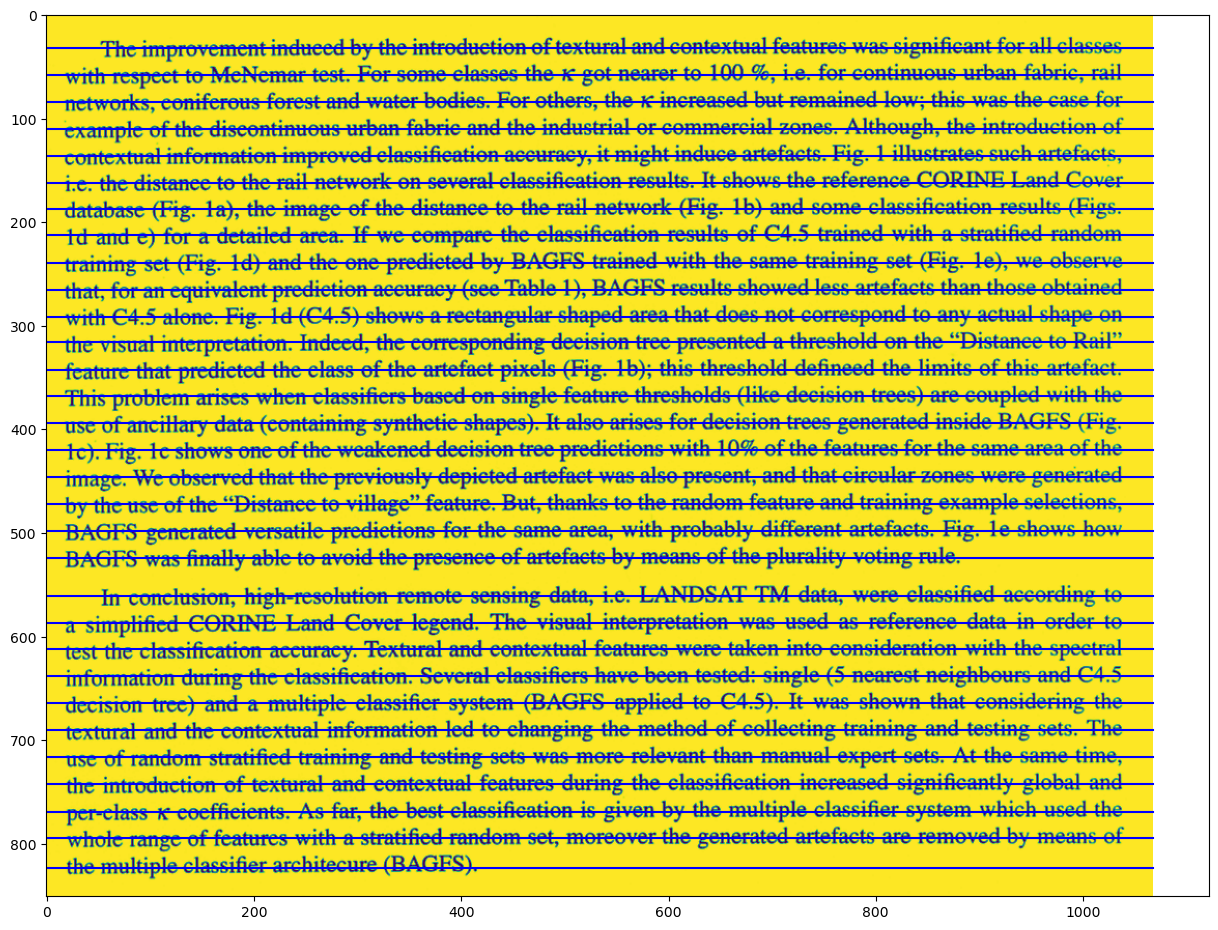

In [339]:
# how can use this information about the bar plot?
# using the peak when extract information about how many object has been detected for corresponding line 


plt.figure(figsize=(15,15))
plt.imshow(im)
for m in maxima:
    plt.plot([0, im.shape[1]], [m, m], 'b-')
plt.show()


# the result show the line for each row of the image text



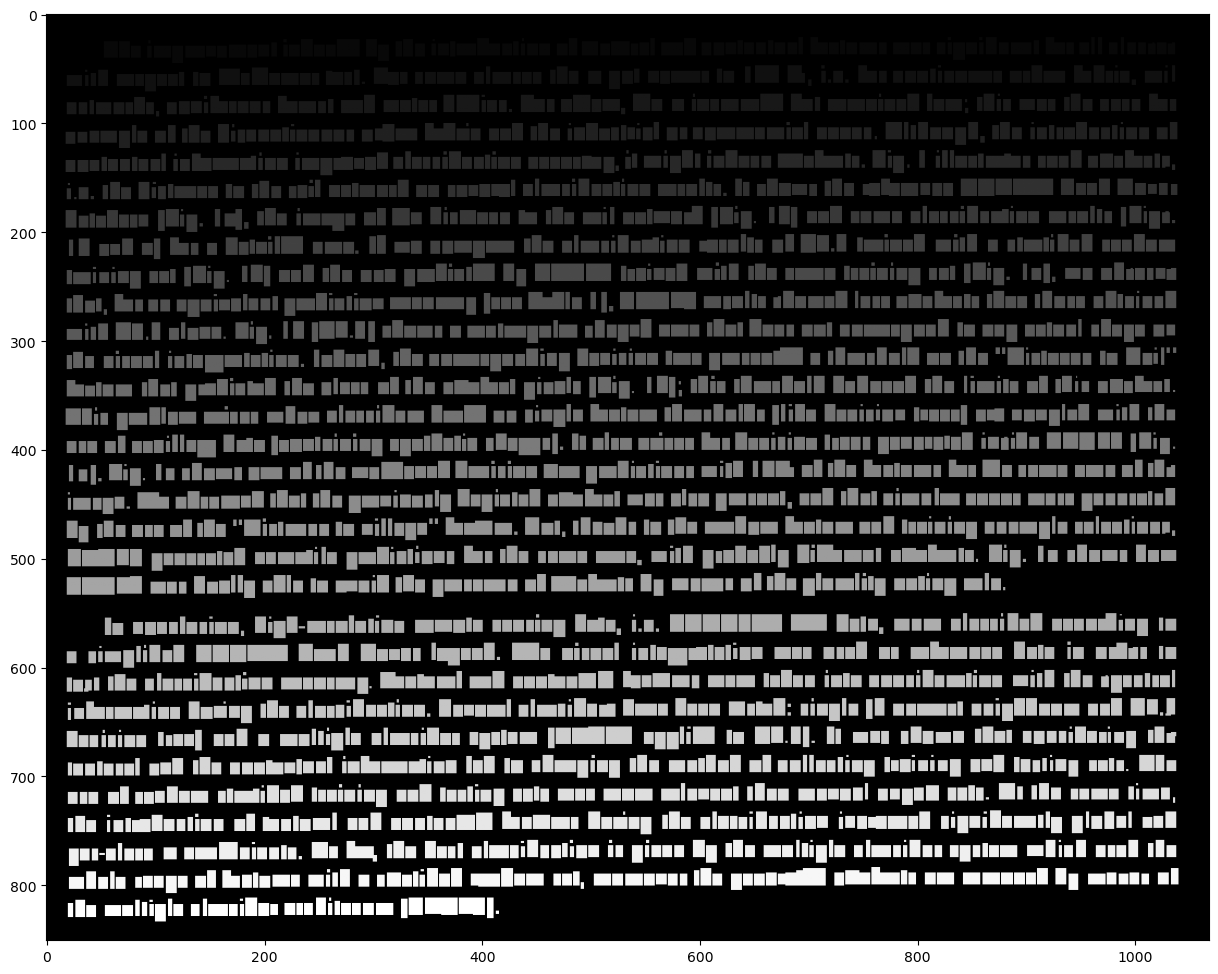

In [340]:
# label to line
label_to_line = [[] for _ in range(len(maxima))]
maxima = np.array(maxima)

plt.figure(figsize=(15,15))
im_lines = np.zeros(im.shape)
for obj in objects_props:
    closet_line = np.abs(obj.centroid[0] - maxima).argmin()
    label_to_line[closet_line].append(obj)
    im_lines[obj.bbox[0]:obj.bbox[2], obj.bbox[1]:obj.bbox[3]] = closet_line+1
    #break 

plt.imshow(im_lines, cmap=plt.cm.gray)
plt.show()

In [341]:
ordered_labels = [[] for _ in range(len(maxima))] 

for i, line_objects in enumerate(label_to_line):
    x_pos = np.array([obj.centroid[1] for obj in line_objects])
    x_order = x_pos.argsort()


    for x in x_order:
        ordered_labels[i].append(line_objects[x])
    print(x_order )

[ 25  26  94  20  95  96  97  98  99 100 101  86  87  88  32  14  89  90
  15  91  92  16  17  93  27  18  71  19  72  73  28  74  75   9  76  77
  29  78  10  79  80  81  11  30  82  31  83  33  12  34  13  35  36  37
  21  38  39  22  40  41   0   1  42  43  23  44  45  46  47  48  49  50
  51   2  52  53  54   3  55   4  56  57  24   5  58  59  60  61   6   7
  62  63   8  64  65  66  67  84  68  69 102  85  70]
[89 20 90 75 21 83 84 85 86 87 88 60 61 76 16 77 14 78 79 80 81 24 62 63
 22 95 15 64 65 66 67 68 69 70 11 71 72 73 74 23 12 25 26 27 28 17 29 30
 31 32 33 18 34 13  0  1 82 91  2 35 92 36 93  3 37 38 39 40 41 19  4 42
 43 44 45 46 47 48 49  5 50  6 51 52  7 53 54  8 55 94 56 57 58 59  9 10]
[82 83 62 84 85 86 20 87 93 88 71 72 17 89 18 73 74 75 76 77 19 78 79 80
 81 25 63 11 64 65 24 66 67 12 13 14 68 69 70 92 15 26 27 28 16 29 30 90
  0 31 32  1 33 34 35 36 37 38  2  3 39 21 40 41 42  4 43 44 45  5  6 46
 47 48 91 22  7 49  8 50 51 52 53 23  9 54 55 56 57 58 59 10 60 61]
[

In [342]:
def get_label_to_line(objects_props, maxima, im_shape):
    label_to_line = [[] for _ in range(len(maxima))]
    im_lines = np.zeros(im_shape)
    for obj in objects_props:
        closet_line = np.abs(obj.centroid[0] - maxima).argmin()
        label_to_line[closet_line].append(obj)
        im_lines[obj.bbox[0]:obj.bbox[2], obj.bbox[1]:obj.bbox[3]] = closet_line+1
    return label_to_line, im_lines


/var/folders/dm/7w0jh4z92gb722hmvw9k3qc00000gn/T/ipykernel_12365/2943791812.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


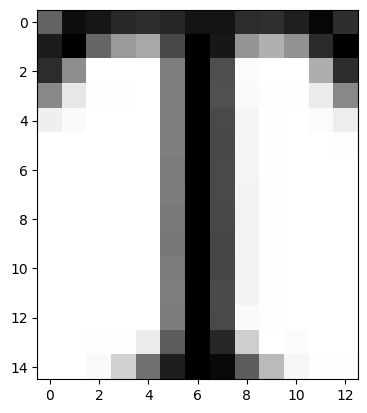

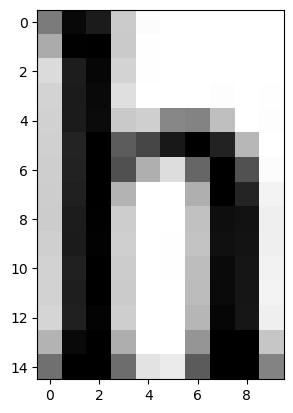

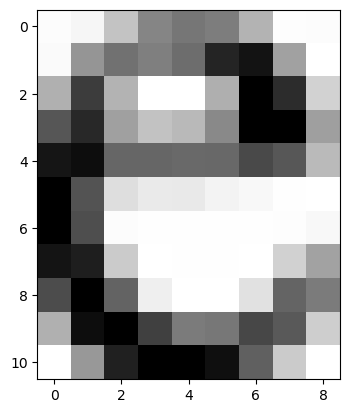

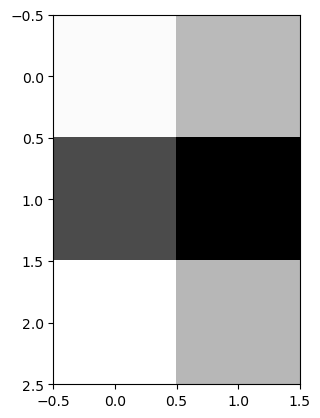

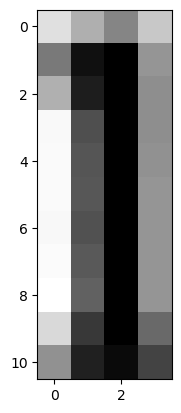

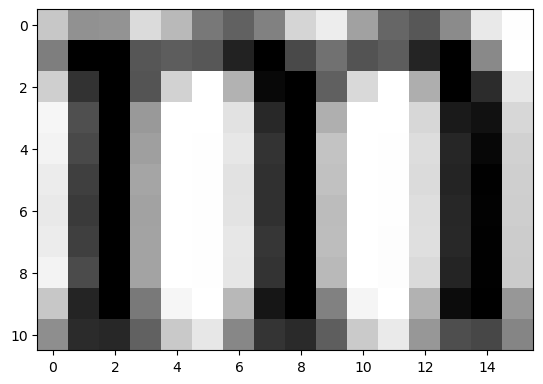

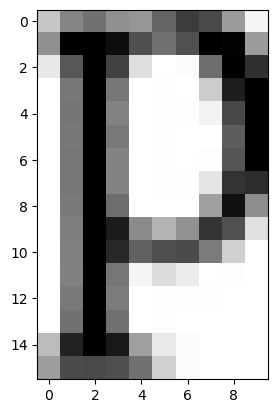

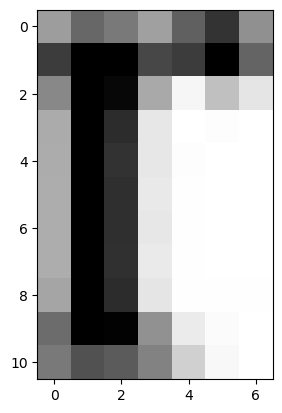

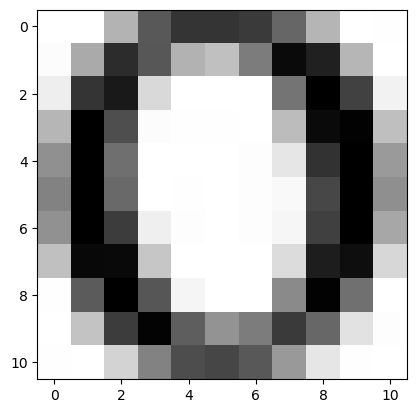

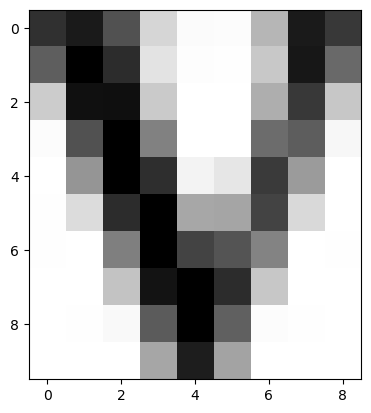

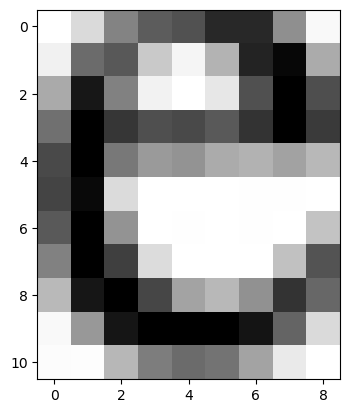

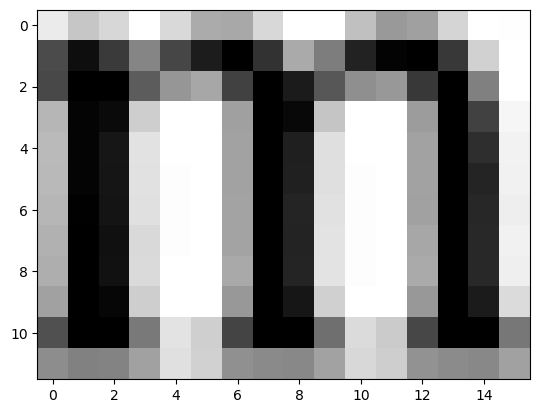

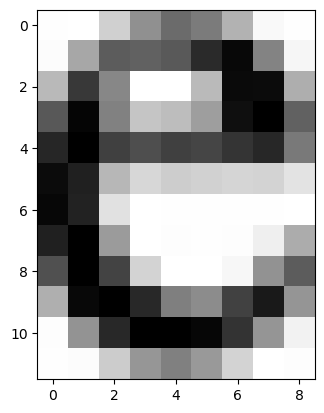

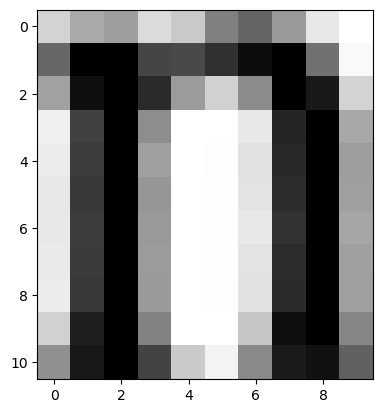

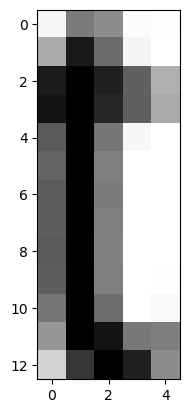

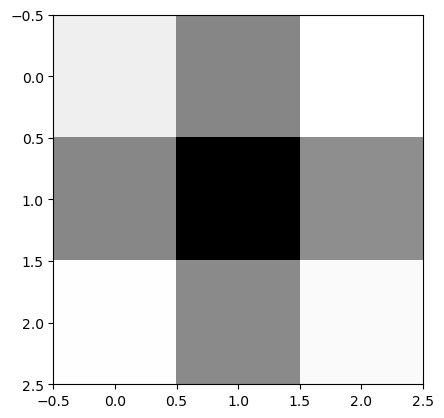

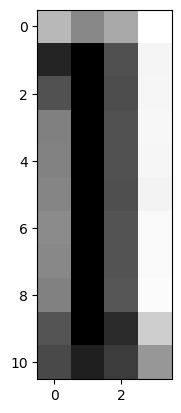

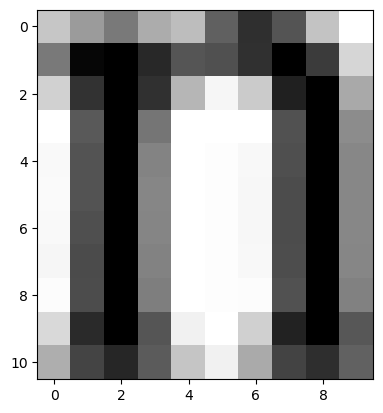

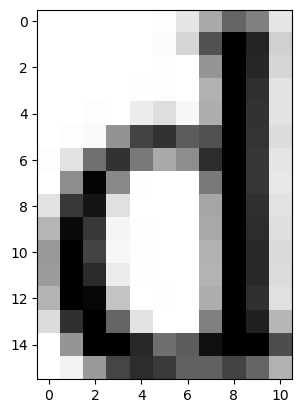

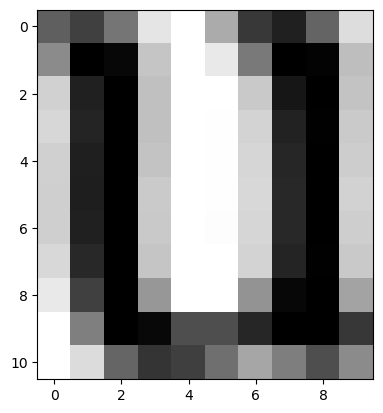

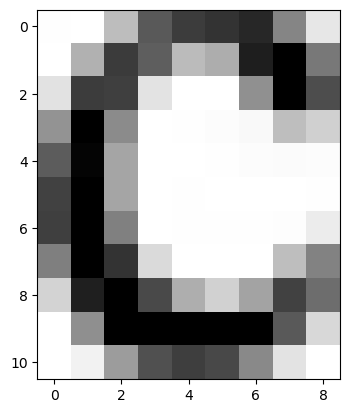

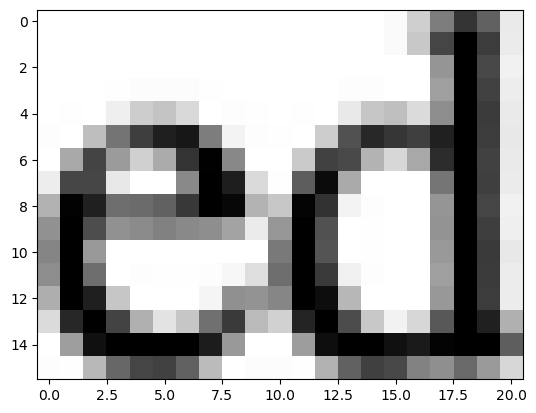

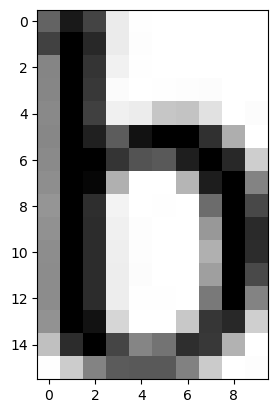

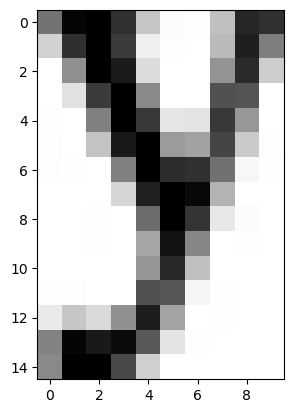

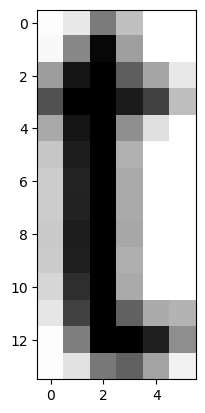

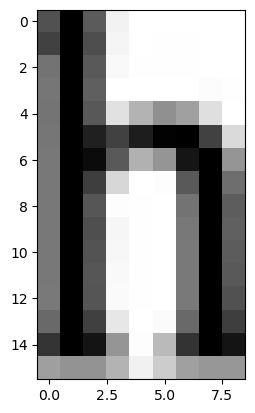

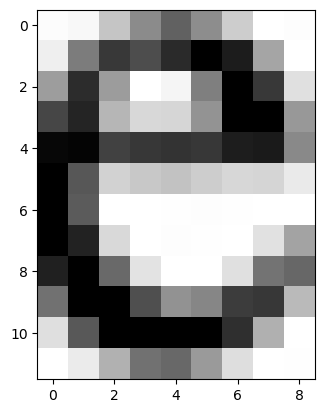

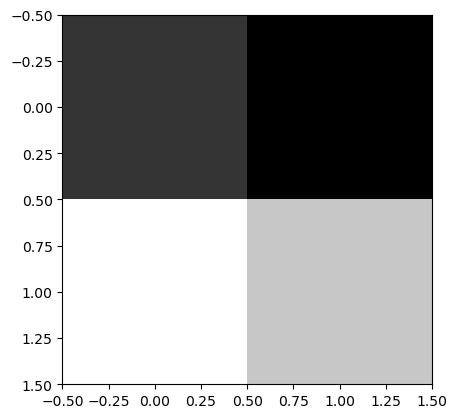

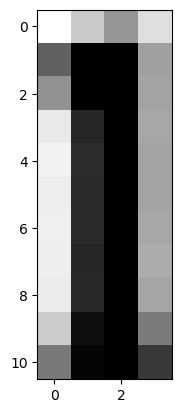

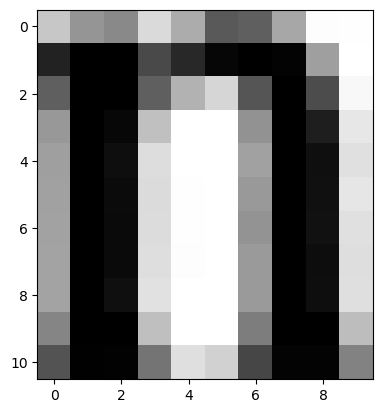

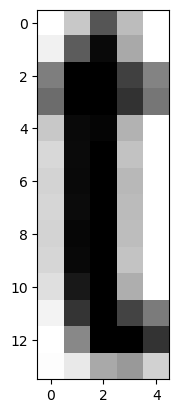

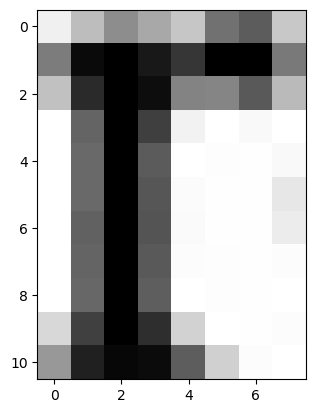

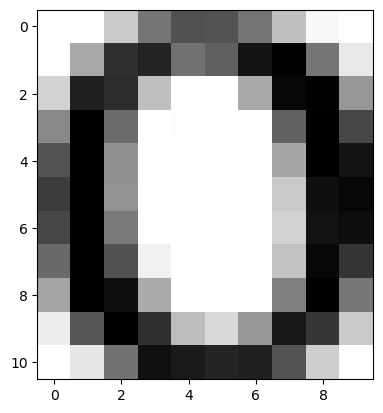

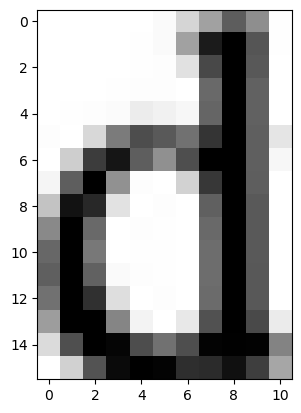

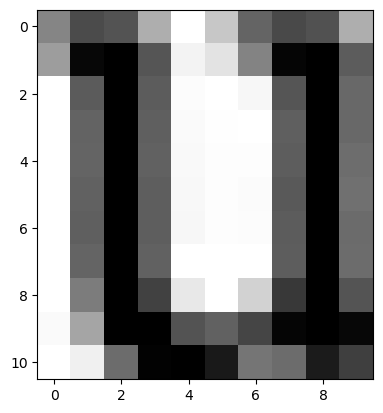

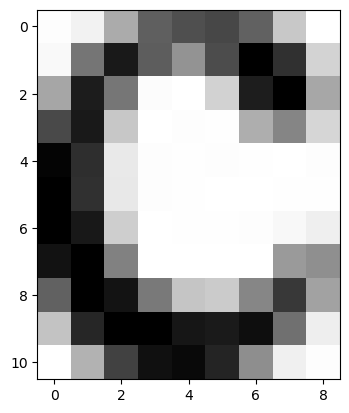

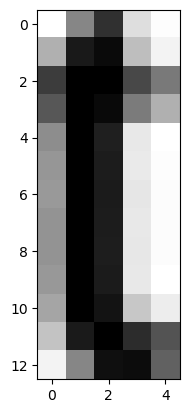

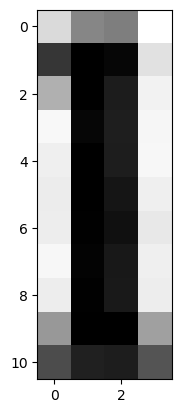

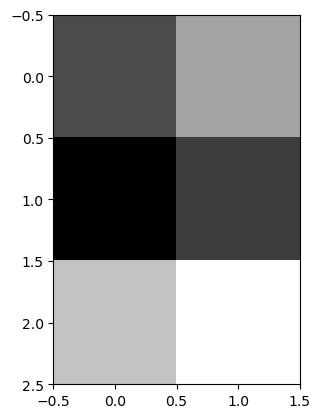

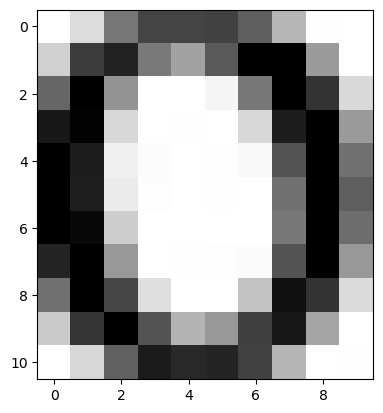

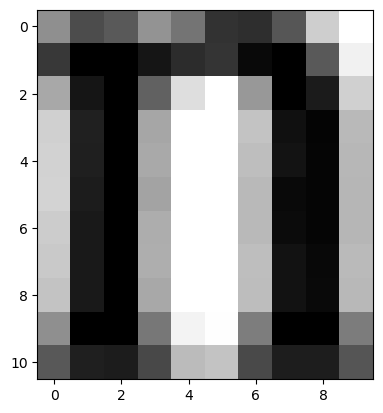

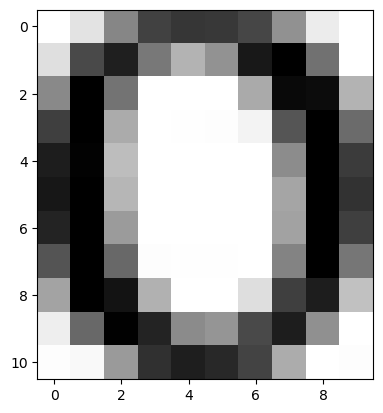

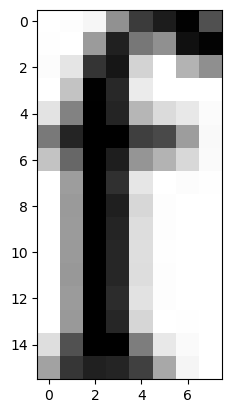

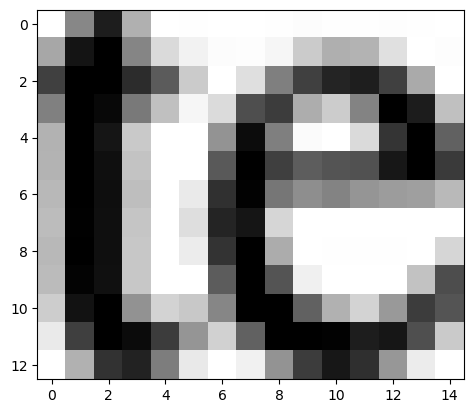

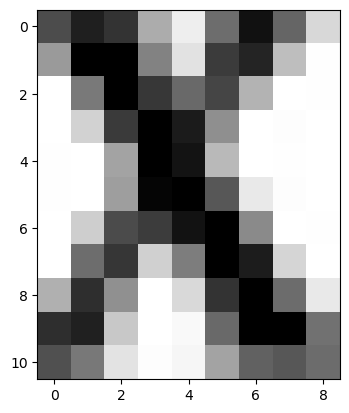

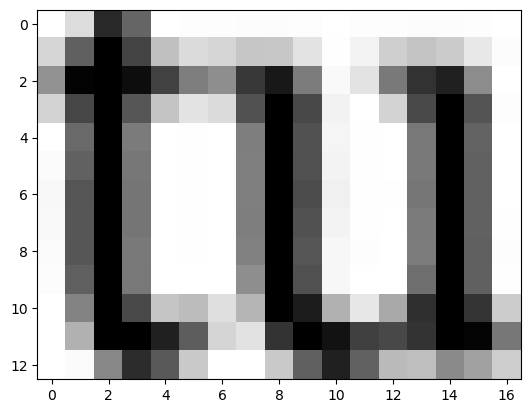

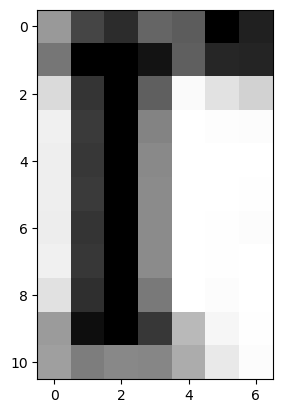

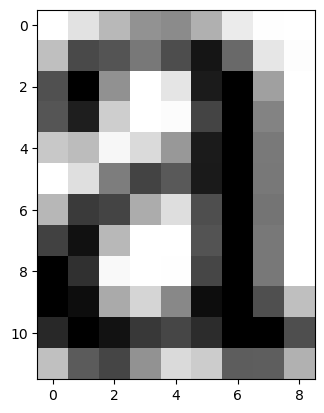

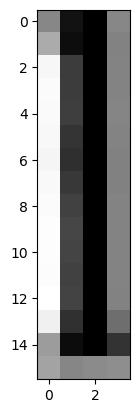

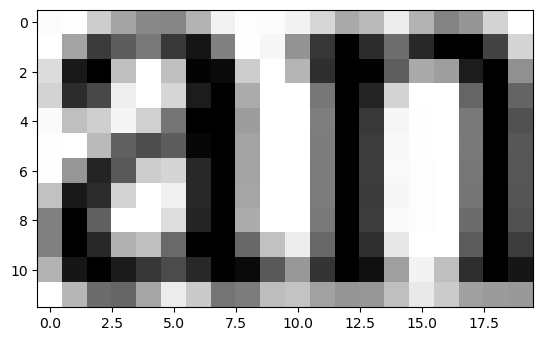

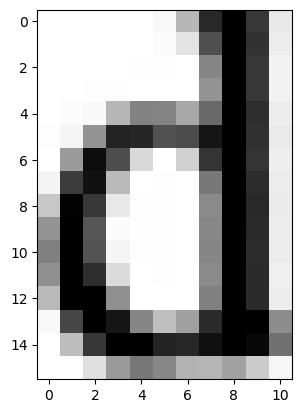

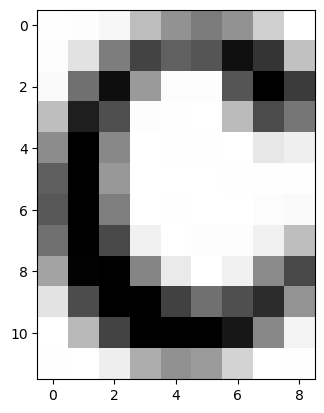

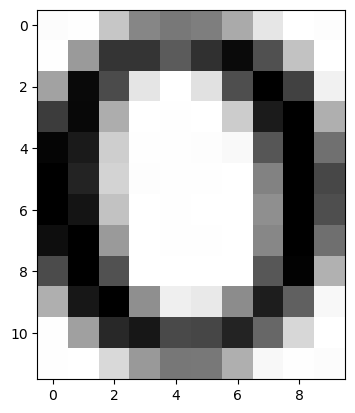

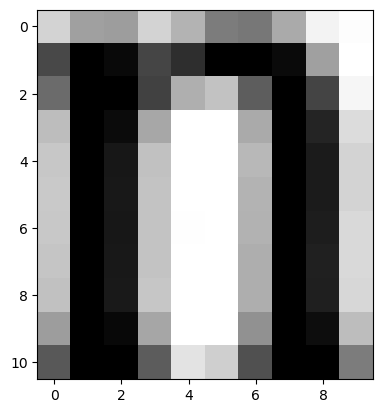

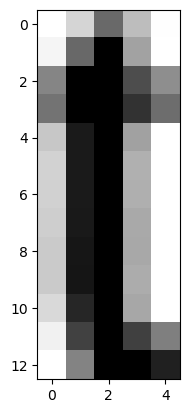

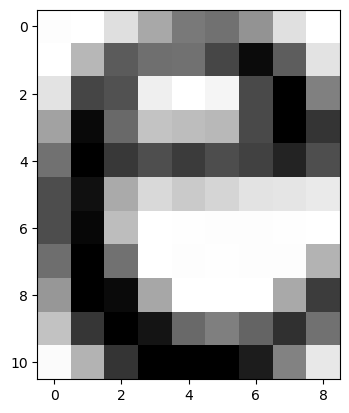

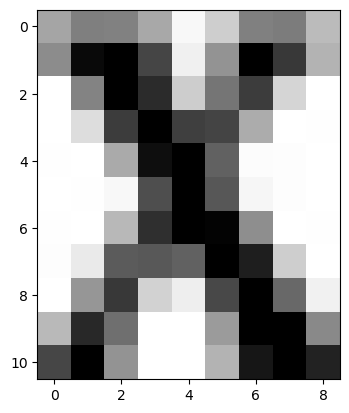

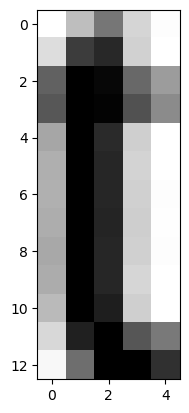

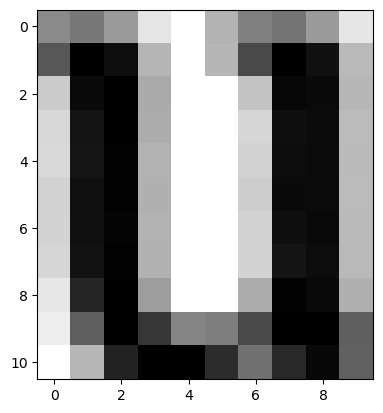

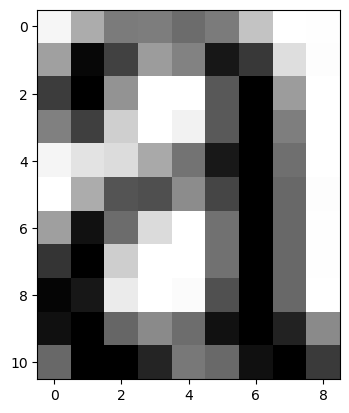

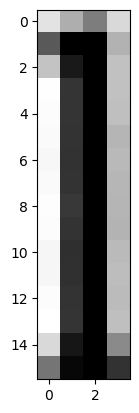

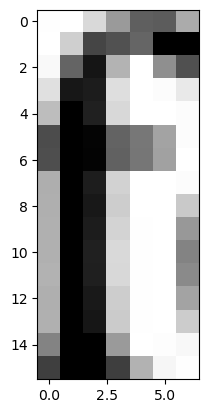

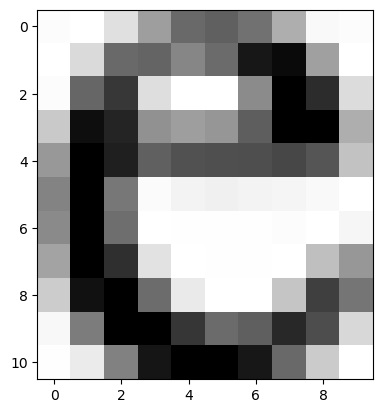

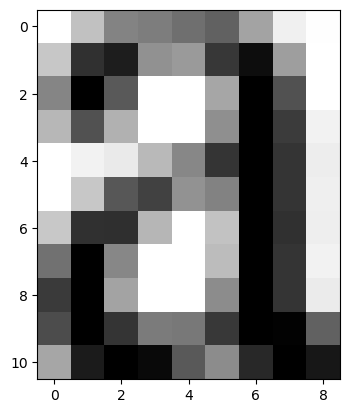

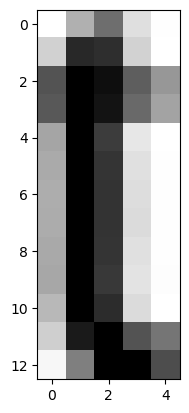

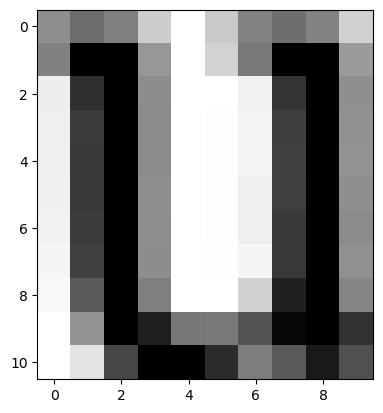

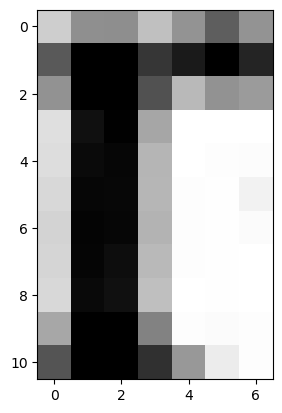

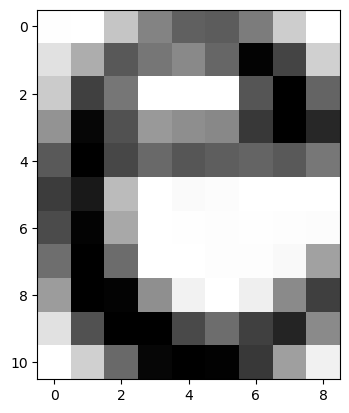

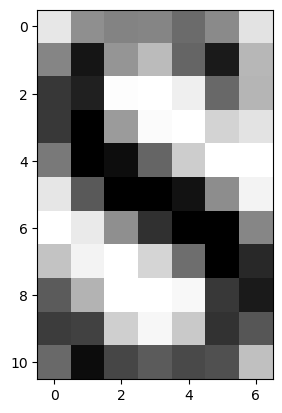

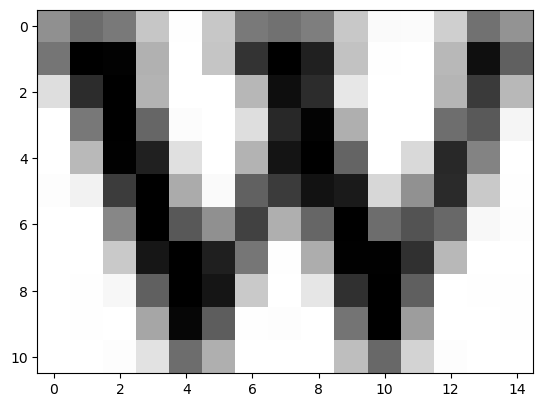

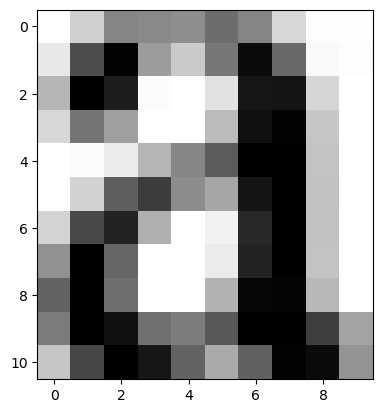

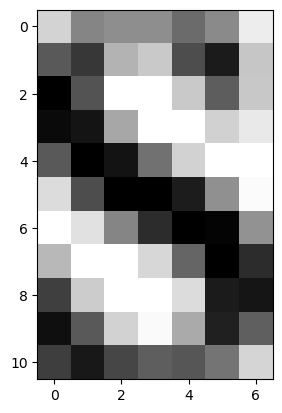

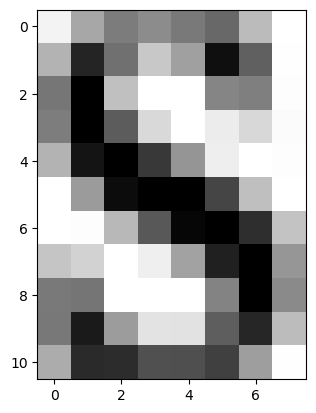

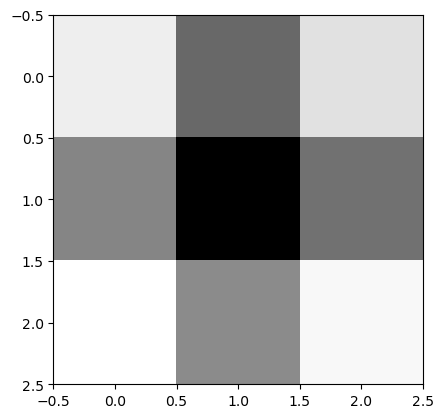

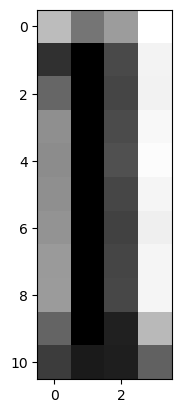

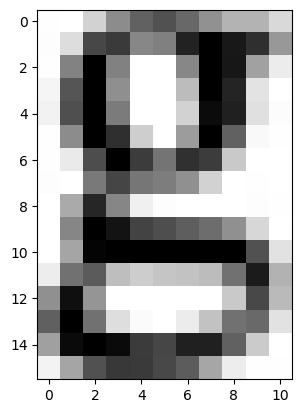

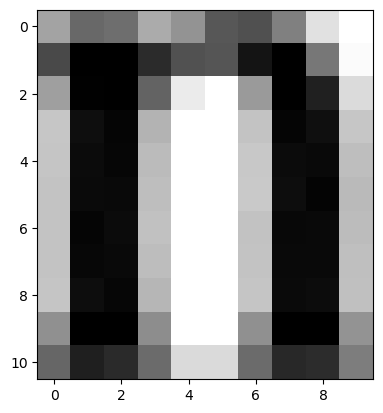

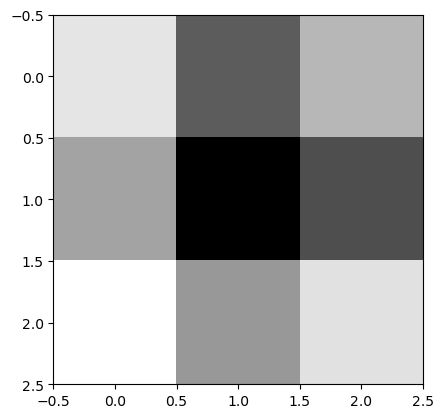

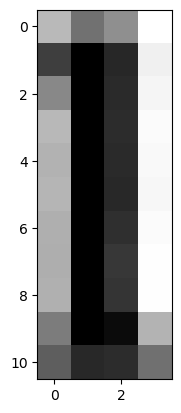

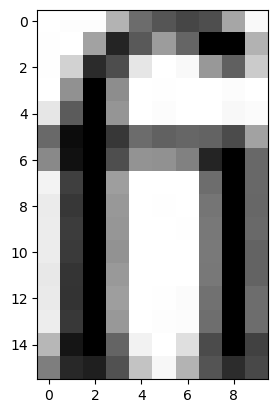

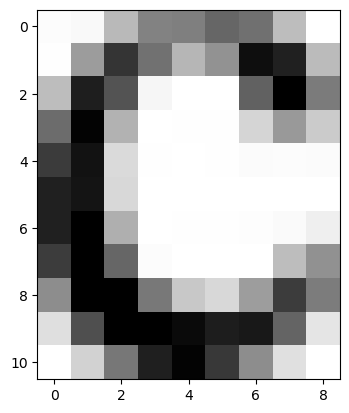

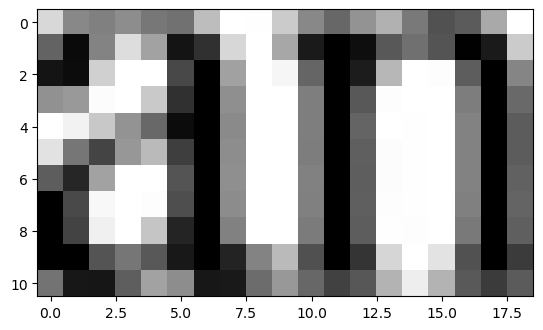

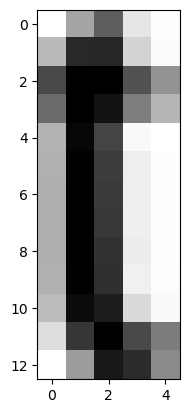

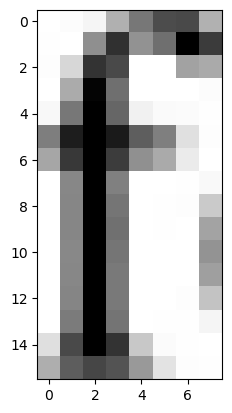

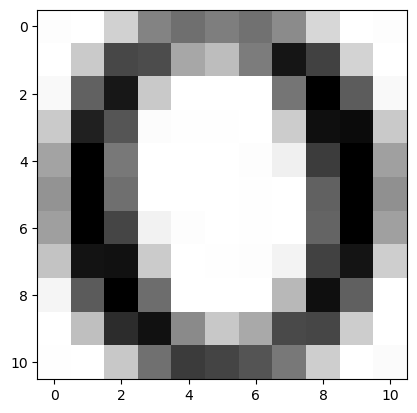

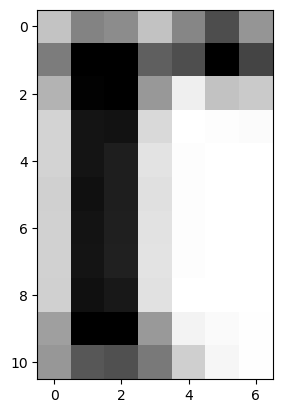

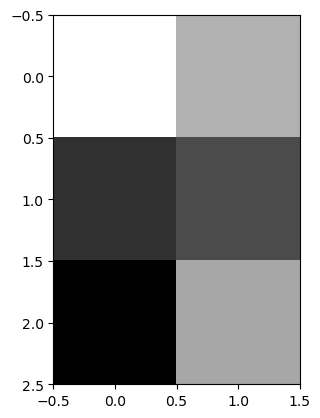

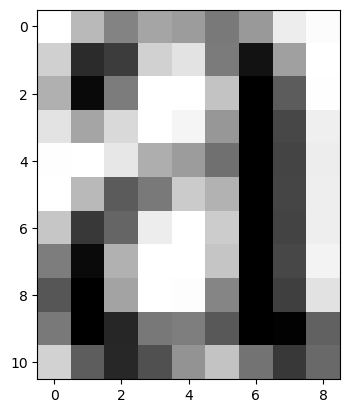

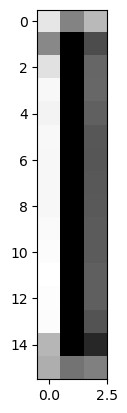

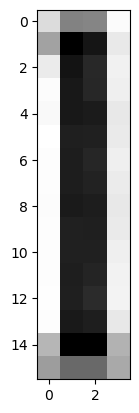

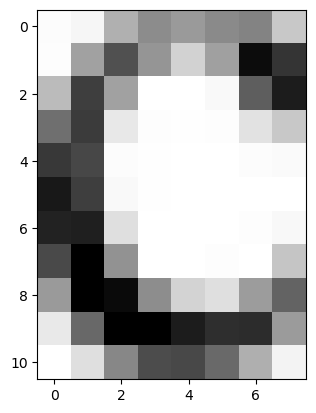

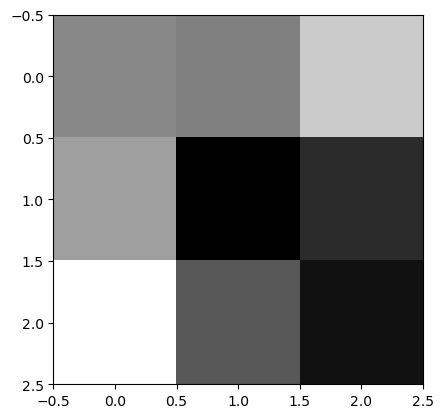

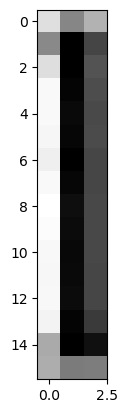

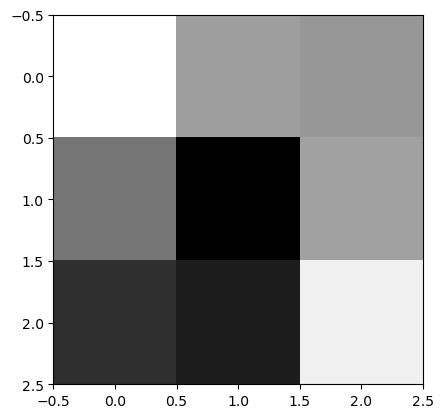

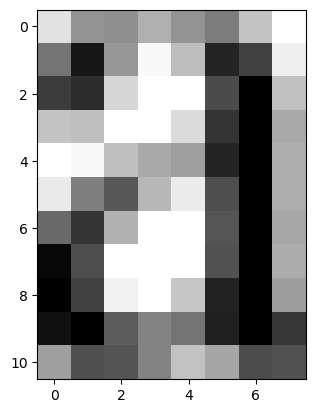

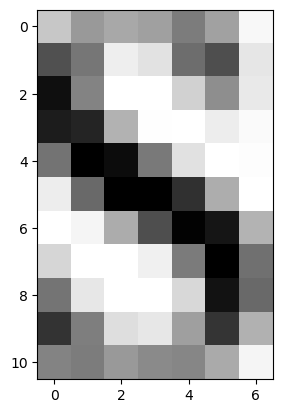

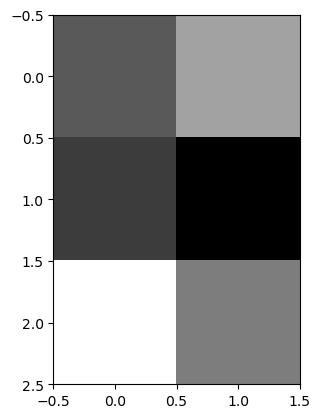

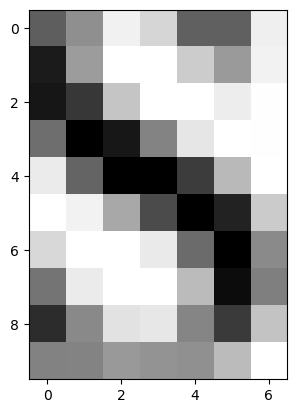

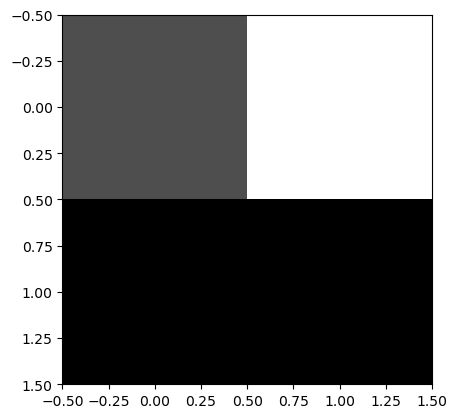

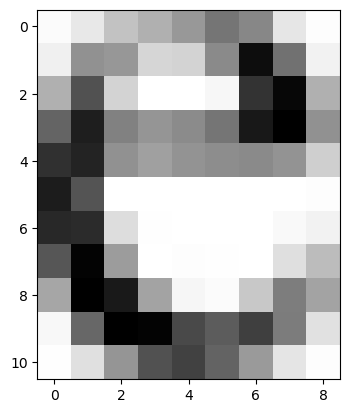

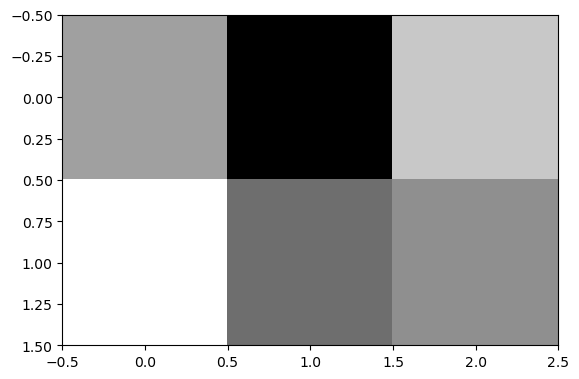

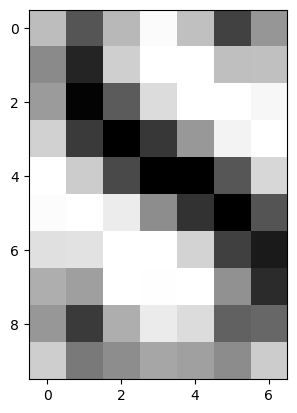

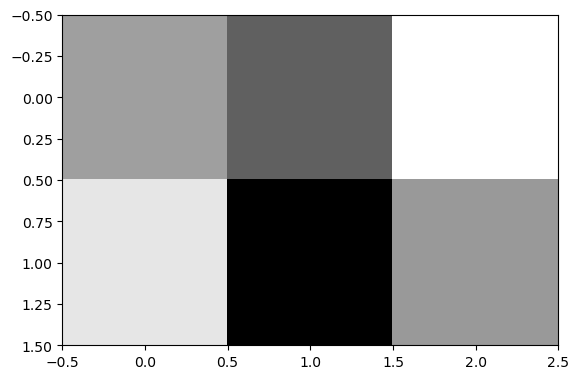

In [343]:
for obj in ordered_labels[0]:
    plt.figure()
    plt.imshow(im[obj.bbox[0]:obj.bbox[2], obj.bbox[1]:obj.bbox[3]], cmap=plt.cm.gray)


# this is going to plot every first row of results

## Expert System classification

* Using the features available with the [regionprops](http://scikit-image.org/docs/dev/api/skimage.measure.html#skimage.measure.regionprops) method of scikit-image, propose a method to automatically recognize some letters.


In [344]:
def expert_system_classifier(region):
    # 1. Extraction of some features
    min_r, min_c, max_r, max_c = region.bbox
    height = max_r - min_r
    width = max_c - min_c
    
   # We also evaluate the aspect ratio. This is useful because different letters have different shapes 
    # (e.g., the letter 'o' has a different aspect ratio compared to 'l').
    aspect_ratio = width / height if height > 0 else 0
    euler = region.euler_number
    solidity = region.solidity
    eccentricity = region.eccentricity
    extent = region.extent
    hu_moments = region.moments_hu
    
    # Letter used for missing value of this OCR
    lettera = "_" 
    
    # Branch to detect some letter with a single hole
    if euler == 0:
        if 0.85 <= aspect_ratio <= 1.15 and solidity > 0.90:
            lettera = "o"
            
        # there is an hole but the shape is different in height
        elif aspect_ratio < 0.70:
            # checking hu_moments
            if hu_moments[6] > 0: 
                lettera = "d"
            else:
                lettera = "b"

    # Branch for letter without any holes
    elif euler == 1:
        # checking between l and 1
        if aspect_ratio < 0.35 and extent > 0.80:
            lettera = "l"
            
        elif 0.80 <= aspect_ratio <= 1.10 and solidity < 0.85:
            lettera = "c"
            
        elif aspect_ratio > 1.3:
            lettera = "m"

        
    return lettera

In [345]:
result = []

for line in ordered_labels:
    for obj in line:
        lettera = expert_system_classifier(obj)
        result.append(lettera)
    result.append("\n")  

print("".join(result))



c____mb__c_m_c___cdcc_d______c___bcc____c___cm____b__c__c_c______c___m______c___c______c___________cm_m
m_______b_c_____c_m______mc____m_c________c___c___________________c_c_m_cc_c_c_d____b___cc__c___
c________c_c______c________b_____b_m________c_m_c_c__c_____bc__m___c_b__m_______m________m____
_c_md_______b___c_c_m_cc_c_c_b___bc_c_cb_____cbc_________c_mm__c____c_c________c________c___bc_____c__
c_c__c_c____c__m_____c__mb__c_dc_______c_____c_ccc__c_____m_______cbc______c____m________c_______cc__c__c____m_
________bm____c___________c_______c__c____c______c_____c___c_________m_________c__c__mc__cbc_c__
b___d__________________m_____c_d____c___________c__m__________b__cb__m_c_____________c___c_______l___m_
_b_cb______b_____________m___mb_____c______c_____c___c_____c________c_b_______________b_ccb_m
____mlc__c___________b__cb____c_d_d__c__b___c_______c_b________________c__c______________mc_d__c_ccc
________cc_dcm_c___c_d__bm_c_m__c_ccc_______c_b____c__cc___c_________dl____c_________c______b

In [346]:
# the result is complete unfair 

In [347]:
def get_ordered_labels(label_to_line):
    ordered_labels = [[] for _ in range(len(maxima))] 
    for i, line_objects in enumerate(label_to_line):
        x_pos = np.array([obj.centroid[1] for obj in line_objects])
        x_order = x_pos.argsort()
        for x in x_order:
            ordered_labels[i].append(line_objects[x])
    return ordered_labels

In [348]:
# Attempt 2 (to improve perfomance on recognize the letter we are going to use a simple supervised classifier for detecting the letter)

# In practice i will use a simple knn classifier trained with some sample that i'm going to generate by myself, but this dataset is 
# modified by adding on the same image some rotation to improve robusteness during the testset

import numpy as np
from PIL import Image, ImageDraw, ImageFont
from skimage import measure
import matplotlib.pyplot as plt

import numpy as np

from skimage.transform import resize

def extract_features(region):
    # Extraction of features
    min_r, min_c, max_r, max_c = region.bbox
    altezza = max_r - min_r
    larghezza = max_c - min_c
    aspect_ratio = larghezza / altezza

    # extractio of image masl
    img_mask = region.image.astype(float) 
    
    
    # resize is a function used for resize a letter and apply anti_aliasing to smoothing result
    # this resize pick the bounding box and map into 20 x 20 pixels
    img_standard = resize(img_mask, (20, 20), anti_aliasing=True)
    
    
    # Extraction of pixels features
    pixel_features = img_standard.flatten()

    # list of other features to taking care
    geom_features = [
        region.eccentricity,
        region.euler_number,
        region.extent,
        region.solidity
    ]
    geom_features.extend(list(region.moments_hu))
    features = [aspect_ratio] + geom_features + list(pixel_features)
    
    return np.array(features, dtype=float)

def generate_and_loading_dataset(font_path, font_size):
    alphabet = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"

    # this what wa want to generate as image
    
    X = []
    y = []
    
    font = ImageFont.truetype(font_path, font_size)

    canvas_size = (100, 100)


    # we define a set of this angles rotation that we used for genrating new image with applied rotations
    angles_rotations = list(range(-15, 16, 5))

    for char in alphabet:
        for angolo in angles_rotations:
            # setup of background (white = 255)
            img = Image.new('L', (120, 120), color=255)
            draw = ImageDraw.Draw(img)
            
            # setup for text (black = 0)
            draw.text((40, 40), char, font=font, fill=0)
            
            
            # the applied rotation produce the new angles, this is a noise for the feature set (so we refill that as white)
            img_rotated = img.rotate(angolo, expand=False, fillcolor=255)
            
            img_array = np.array(img_rotated)
            
            
            # now we filter the image (as we did for separation between back and foreground)
            binary_image = img_array < 128
            
                
            # Now let's to exctract the features of the image generated previously
            single_label_image = binary_image.astype(int)
            composed_region = measure.regionprops(single_label_image)[0]
            
            feature_vector = extract_features(composed_region)
            
            X.append(feature_vector)
            y.append(char)

    
    return np.array(X), np.array(y)

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import numpy as np

def train_ocr_model(font_path="Arial.ttf", font_size=22):
    
    # Loading of the syntethic dataset
    X_train, y_train = generate_and_loading_dataset(font_path, font_size=font_size)
    
        
    print(f"Dataset of: {X_train.shape[0]} samples, {X_train.shape[1]} features")

    # Encoding of the letter (y)
    encoder = LabelEncoder()
    y_train_transformed = encoder.fit_transform(y_train)

    # Setup of the pipeline for scaling the value and for tuning the classifier

    # Pipeline is a simple function defined to decide the steps for performing a complete grid search
    pipeline = Pipeline([
        ('scaler', StandardScaler()), # using for scaling the value 
        ('knn', KNeighborsClassifier()) # classfier to be tuned 
    ])

    param_grid = {
        'knn__n_neighbors': [1, 3, 5, 7],
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['euclidean', 'manhattan'] 
    }

    # instead of use like during the machine learning manually the search of a best parameter to use (we use the grid search that is a simple function for 
    # tuning every parameters)
    grid_search = GridSearchCV(
        pipeline, 
        param_grid, 
        cv=5, 
        scoring='accuracy', 
        n_jobs=-1 
    )

    grid_search.fit(X_train, y_train_transformed) 

    print(f"Best parameters found: {grid_search.best_params_}")
    print(f"Accuracy achieved: {grid_search.best_score_ * 100:.2f}%\n")

    # Extrction of the model
    model = grid_search.best_estimator_

    return model, encoder


# Decoding phase
def decode_text(ordered_labels, model, encoder):
    text = ""

    for line in ordered_labels:
        # initiliazation of the spacing
        previous_max_c = None 
        
        for obj in line:
            # Extraction of the coordinates of ojects box
            min_r, min_c, max_r, max_c = obj.bbox
            height_letter = max_r - min_r
            
            # if the previous_max_c is already defined mean there was a previous spacing before  
            if previous_max_c is not None:
                horizontal_distance = min_c - previous_max_c
                if horizontal_distance > (height_letter * 0.25):
                    text += " "

            previous_max_c = max_c
            
            # Extraction and reshaping of features
            feature_vector = extract_features(obj)
            feature_reshaped = feature_vector.reshape(1, -1)
            
            # Scaling + prediction
            predicted_char_id = model.predict(feature_reshaped)[0]
            
            # Conversion for the real letter predicted
            pred_array = encoder.inverse_transform([predicted_char_id])
            text += pred_array[0]
            
        text += "\n"

    return text

## Full OCR pipeline

Using all the previous exercices, create a method that takes as input a text image, and outputs the recognized text.

In [ ]:
def OCR(im, font_path, font_size):
    img = read_image(im)
    segmented = get_segmented_image(img)
    label_image = get_label_image(segmented)
    objects_props = get_objects_properties(label_image)
    centroid_ys = get_centroid_ys(objects_props, img)
    maxima = line_maxima(centroid_ys)
    label_to_line, im_lines = get_label_to_line(objects_props, maxima, img.shape)
    ordered = get_ordered_labels(label_to_line)
    model, encoder = train_ocr_model(font_path=font_path, font_size=font_size)
    text_decoded = decode_text(ordered, model, encoder)
    return text_decoded

In [ ]:
# To perform the analysis i will use two different font and font size that i discovered during the analysis, 
# in paticular for the doc1.png (provided my lab) i have used Arial as font type and a sizee of 20

# While for second image i have used FreeSerif and a font size of 22, and this different implementation is usefull for the classifier 

In [ ]:
#print(OCR("../data/doc.png", font_path="Arial.ttf", font_size=20))

Dataset of: 434 samples, 412 features
Best parameters found: {'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Accuracy achieved: 80.87%

The llmprovcmcnI IInducV by thc llnIroducIll on of mxmral ad contextuaI reatures w8s s II8n lI6cMt ror ialI cll ldSl sic lIl
w llIh respccr ro MCNem8r lcsI l For some clBses Ihc r 8ot nc8er Io jm To I ll le l ror conI llnuous urbz rldbrIlc I r ldll l
neIwOrks l con llrer0us rorcsI Md waIer bV llcs l For omcnj me r lIncread but mma llned low ll Ihll s was Ihc caslc rOr
cx8mpIe or Ihc d ilsconI llnuous urbz r8bnlc and rhc llndusIr llaI 0r commerc lIal zoaes l AIthou8h t Ihe ll ntroduCtIl 0n 0r
C0ntexLual ll nrometll on ll mproved cIass ll6caIllon accuracyl ilt m ll8hI iInduce vcr8cIs l F II8 l j llllustBrcs such ancraCt iIl l
ll le i thc d llsIzce Io rhc ra ilI network oa scveral cIas ll6catll on resulIs l lI shows thc rercmncc C0kx L land C0ve r
daIabase rF ll8 l j aj I the ll ma8c or me dIl sbnce Lo Ihe n llI acIwork rF l

In [ ]:
print(OCR("ocr.png", font_path="FreeSerif.ttf", font_size=22))

Dataset of: 434 samples, 412 features
Best parameters found: {'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Accuracy achieved: 78.79%

a r a l a a a a a
AI ass1sfance Produccs s1gn1Hcanf PtOducr1v1ry ga1ns actOss PtOfoss1onaI dOma1ns l Parr1cu1arIy fOt
a l l l a a I
H0Vlce WOtkot8 l Yof hOW fhI8 assIsfanc0 ag0cfs fh0 dovol0PmeHf of skI1Is toqultod fO oJecflv01y 8uP0tv18e
a l a l I l
AI t0malns uncIeat 1 NovIc0 Wotk0ts Who t0Iy h0avlIy on AI fO comP10f0 uHfamIl1at fasks may cOmPtomIse
a a a l a a l a
1h01t OwH sk1Il acqu1sIf1on 1n fhc PtOcOss s wO cOHducf tandOmIzcd OxP0t1menf8 1O sfudy hoW develoPOts
a a l r r a
ga1ned masfcty of a noW bynchtOnOus Progtamm1ng 11btaty W1fh and W1fhour fho ass1sfanco of AI a
l r a a r r a l a
wo Hnd fhaf AI uso 1mPa1ts concoPfua1 undotsfand1ng l codo tcad1ng J and dobugg1ng ab111f1os J W1fhOuf
r I I a I a a I a
dOI1Vot1ng s1gn1hcanf omc1oncy ga1ns on avOtagO a Patf1c1Panrs Who fuI1y doIogafod cod1ng fasks shOWod
a a l r r 

In [ ]:
# This result is better than the previous the are implmented following the rule and if-statement
# we get a good result and sometimes we can see some word in the sentence